<a href="https://colab.research.google.com/github/prakashrock0510-ni/project-3_hr_job_placement/blob/main/Project_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
df = pd.read_csv("/content/HR_Job_Placement_Dataset.csv")

In [ ]:
df.describe()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months
count,51500.000000,48919.000000,49435.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,49918.000000,50403.000000
mean,27.505456,70.002505,72.060636,74.010825,68.027499,64.005715,66.106692,73.937491,1.400136,1.494117,4.844616,8.002649,20.095457,3.056187
std,4.025385,7.976314,7.916654,6.945579,11.855145,9.922397,9.907488,11.794258,1.184387,1.375508,2.125294,3.133792,24.852660,4.431784
min,21.000000,50.000000,50.000000,55.000000,40.000000,40.000000,45.000000,45.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000
25%,24.000000,64.574733,66.720058,69.305041,59.935988,57.204237,59.252271,65.851924,1.000000,0.000000,3.325635,5.672655,0.000000,0.000000
50%,27.000000,69.971210,72.014383,73.998187,67.986042,63.972079,66.033268,74.001772,1.000000,1.000000,4.807598,7.857337,15.000000,0.000000
75%,31.000000,75.389057,77.389894,78.707827,76.049235,70.727134,72.840985,82.112773,2.000000,2.000000,6.297570,10.093509,30.000000,6.000000
max,34.000000,95.000000,95.000000,95.000000,100.000000,100.000000,100.000000,100.000000,8.000000,5.000000,13.844566,26.524634,90.000000,18.000000


In [ ]:
df.shape

(51500, 26)

In [ ]:
df.isnull().sum()

,0
age_years,0
gender,0
ssc_percentage,2581
hsc_percentage,2065
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df.duplicated().sum()

np.int64(1376)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()


np.int64(0)

In [ ]:
df.reset_index(drop=True, inplace=True)

In [ ]:
(df.columns.tolist())

['age_years',
 'gender',
 'ssc_percentage',
 'hsc_percentage',
 'degree_percentage',
 'degree_specialization',
 'technical_score',
 'aptitude_score',
 'communication_score',
 'skills_match_percentage',
 'certifications_count',
 'internship_experience',
 'years_of_experience',
 'career_switch_willingness',
 'relevant_experience',
 'previous_ctc_lpa',
 'expected_ctc_lpa',
 'company_tier',
 'job_role_match',
 'competition_level',
 'bond_requirement',
 'notice_period_days',
 'layoff_history',
 'employment_gap_months',
 'relocation_willingness',
 'status']

In [ ]:
df.isnull().sum()

,0
age_years,0
gender,0
ssc_percentage,2509
hsc_percentage,2006
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


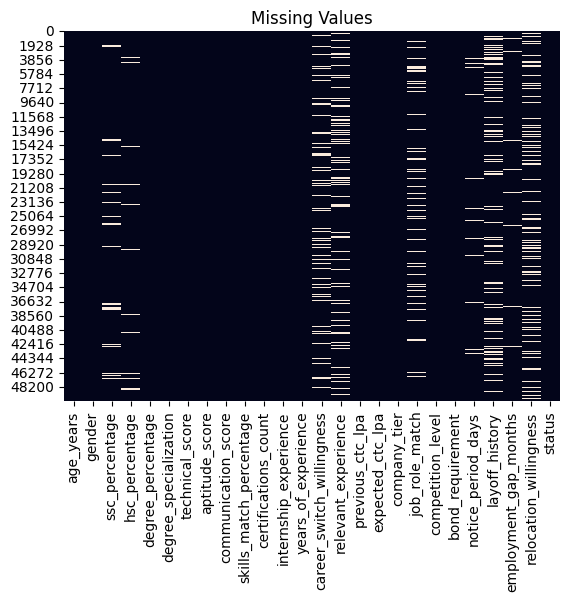

In [ ]:
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

In [ ]:
df["status"].value_counts()

,count
status,
Not Placed,34950
Placed,15174


In [ ]:
numeric_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "technical_score",
    "aptitude_score",
    "communication_score",
    "skills_match_percentage",
    "years_of_experience",
    "expected_ctc_lpa"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)

age_years                      int64
gender                        object
ssc_percentage               float64
hsc_percentage               float64
degree_percentage            float64
degree_specialization         object
technical_score              float64
aptitude_score               float64
communication_score          float64
skills_match_percentage      float64
certifications_count           int64
internship_experience         object
years_of_experience            int64
career_switch_willingness     object
relevant_experience           object
previous_ctc_lpa             float64
expected_ctc_lpa             float64
company_tier                  object
job_role_match                object
competition_level             object
bond_requirement              object
notice_period_days           float64
layoff_history                object
employment_gap_months        float64
relocation_willingness        object
status                        object
dtype: object


In [ ]:
df["ssc_percentage"] = df["ssc_percentage"].fillna(df["ssc_percentage"].median())

In [ ]:
df["hsc_percentage"] = df["hsc_percentage"].fillna(df["hsc_percentage"].median())


In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["career_switch_willingness"].value_counts()

,count
career_switch_willingness,
Not Willing,27707
Willing,14175


In [ ]:
df["career_switch_willingness"] = (df["career_switch_willingness"].fillna("Unknown"))

In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["relevant_experience"].value_counts()

,count
relevant_experience,
Relevant,25597
Not Relevant,16328


In [ ]:
df["relevant_experience"] = (df["relevant_experience"].fillna("Unknown"))

In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["job_role_match"].value_counts()

,count
job_role_match,
Matched,32557
Not Matched,11603


In [ ]:
df["job_role_match"] = df["job_role_match"].fillna("Unknown")

In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["notice_period_days"].value_counts()

,count
notice_period_days,
0.0,21137
30.0,9971
15.0,9900
60.0,5095
90.0,2483


In [ ]:
df["notice_period_days"] = df["notice_period_days"].fillna(df["notice_period_days"].median())

In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["layoff_history"].value_counts()

,count
layoff_history,
No,36328
Yes,5537


In [ ]:
df["layoff_history"] = df["layoff_history"].fillna(df["layoff_history"].mode()[0])

In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["employment_gap_months"].value_counts()

,count
employment_gap_months,
0.0,25967
3.0,10152
6.0,7456
12.0,3952
18.0,1523


In [ ]:
df["employment_gap_months"] = df["employment_gap_months"].fillna(df["employment_gap_months"].median())

In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
df["relocation_willingness"].value_counts()

,count
relocation_willingness,
Willing,27061
Not Willing,14816


In [ ]:
df["relocation_willingness"] = df["relocation_willingness"].fillna(df["relocation_willingness"].mode()[0])


In [ ]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,0
hsc_percentage,0
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [ ]:
for col in df.select_dtypes(include=np.number).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, "Outliers:", len(outliers))

age_years Outliers: 0
ssc_percentage Outliers: 269
hsc_percentage Outliers: 518
degree_percentage Outliers: 366
technical_score Outliers: 0
aptitude_score Outliers: 181
communication_score Outliers: 162
skills_match_percentage Outliers: 0
certifications_count Outliers: 2704
years_of_experience Outliers: 0
previous_ctc_lpa Outliers: 180
expected_ctc_lpa Outliers: 297
notice_period_days Outliers: 2483
employment_gap_months Outliers: 1523


In [ ]:
Q1 = df["ssc_percentage"].quantile(0.25)
Q3 = df["ssc_percentage"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Lower limit:", lower)
print("Upper limit:", upper)
outliers = df[(df["ssc_percentage"] < lower) |(df["ssc_percentage"] > upper)]
print("Number of outliers:", len(outliers))
print(outliers[["ssc_percentage"]].sort_values("ssc_percentage"))

Lower limit: 49.63230283499998
Upper limit: 90.34473231500002
Number of outliers: 269
       ssc_percentage
14794       90.359864
568         90.360795
32448       90.360970
38700       90.369505
1317        90.377516
...               ...
42582       95.000000
4771        95.000000
4124        95.000000
896         95.000000
569         95.000000

[269 rows x 1 columns]


In [ ]:
df["ssc_percentage"] = df["ssc_percentage"].clip(lower=lower,upper=upper)


In [ ]:
Q1_new = df["ssc_percentage"].quantile(0.25)
Q3_new = df["ssc_percentage"].quantile(0.75)
IQR_new = Q3_new - Q1_new
lower_new = Q1_new - 1.5 * IQR_new
upper_new = Q3_new + 1.5 * IQR_new
remaining_outliers = df[(df["ssc_percentage"] < lower_new) |(df["ssc_percentage"] > upper_new)]
print("Outliers before treatment:", len(outliers))
print("Outliers after treatment:", len(remaining_outliers))
print("Minimum percentage:", df["ssc_percentage"].min())
print("Maximum percentage:", df["ssc_percentage"].max())

Outliers before treatment: 269
Outliers after treatment: 0
Minimum percentage: 50.0
Maximum percentage: 90.34473231500002


In [ ]:
Q1 = df["hsc_percentage"].quantile(0.25)
Q3 = df["hsc_percentage"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Lower limit:", lower)
print("Upper limit:", upper)
outliers = df[(df["hsc_percentage"] < lower) |(df["hsc_percentage"] > upper)]
print("Number of outliers:", len(outliers))
print(outliers[["hsc_percentage"]].sort_values("hsc_percentage"))

Lower limit: 51.70246791125002
Upper limit: 92.41196760124998
Number of outliers: 518
       hsc_percentage
320              50.0
49811            50.0
2344             50.0
49592            50.0
516              50.0
...               ...
47876            95.0
47664            95.0
47382            95.0
1961             95.0
49904            95.0

[518 rows x 1 columns]


In [ ]:
df["hsc_percentage"] = df["hsc_percentage"].clip(lower=lower,upper=upper)



In [ ]:
Q1_new = df["hsc_percentage"].quantile(0.25)
Q3_new = df["hsc_percentage"].quantile(0.75)

IQR_new = Q3_new - Q1_new

lower_new = Q1_new - 1.5 * IQR_new
upper_new = Q3_new + 1.5 * IQR_new

remaining = df[
    (df["hsc_percentage"] < lower_new) |
    (df["hsc_percentage"] > upper_new)
]

print("Remaining IQR outliers:", len(remaining))

Remaining IQR outliers: 0


In [ ]:
categorical_columns = df.select_dtypes(include=["object", "string"]).columns
for col in categorical_columns:
    df[col] = df[col].str.strip()
df["status"] = df["status"].str.title()
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))


gender:
gender
Female    23701
Male      23416
female     1504
male       1503
Name: count, dtype: int64

degree_specialization:
degree_specialization
Others                    10174
Electronics               10078
Information Technology    10032
Computer Science           9927
Mechanical                 9913
Name: count, dtype: int64

internship_experience:
internship_experience
No     24902
Yes    22715
no      1314
yes     1193
Name: count, dtype: int64

career_switch_willingness:
career_switch_willingness
Not Willing    27707
Willing        14175
Unknown         8242
Name: count, dtype: int64

relevant_experience:
relevant_experience
Relevant        25597
Not Relevant    16328
Unknown          8199
Name: count, dtype: int64

company_tier:
company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: count, dtype: int64

job_role_match:
job_role_match
Matched        32557
Not Matched    11603
Unknown         5964
Name: count, dtype: int64

competition_level:
competition_level


In [ ]:
score_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "technical_score",
    "aptitude_score",
    "communication_score",
    "skills_match_percentage"
]

for col in score_columns:
    if col in df.columns:
        invalid = (df[col] < 0) | (df[col] > 100)
        print(col, "Invalid values:", invalid.sum())
        df.loc[invalid, col] = np.nan
if "years_of_experience" in df.columns:
    invalid_experience = df["years_of_experience"] < 0
    print("Invalid Experience Values:",invalid_experience.sum())
    df.loc[invalid_experience, "years_of_experience"] = np.nan
if "certifications_count" in df.columns:
    invalid_certifications = df["certifications_count"] < 0
    print("Invalid Certification Values:",invalid_certifications.sum())
    df.loc[invalid_certifications, "certifications_count"] = np.nan

print("Logical consistency checks completed.")

ssc_percentage Invalid values: 0
hsc_percentage Invalid values: 0
degree_percentage Invalid values: 0
technical_score Invalid values: 0
aptitude_score Invalid values: 0
communication_score Invalid values: 0
skills_match_percentage Invalid values: 0
Invalid Experience Values: 0
Invalid Certification Values: 0
Logical consistency checks completed.


In [ ]:
categorical_columns = df.select_dtypes(include=["object", "string"]).columns.drop("status", errors="ignore")
df_encoded = pd.get_dummies(df,columns=categorical_columns,drop_first=True,dtype=int)
df_encoded.head()


,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,...,relevant_experience_Unknown,company_tier_Tier 2,company_tier_Tier 3,job_role_match_Not Matched,job_role_match_Unknown,competition_level_Low,competition_level_Medium,bond_requirement_Required,layoff_history_Yes,relocation_willingness_Willing
0,27,65.061656,83.842578,75.856526,58.221909,89.566305,64.474484,79.548913,2.0,1.0,...,0,0,1,1,0,0,1,0,0,0
1,24,67.885626,64.973305,73.093588,71.927978,54.591971,61.077306,73.316134,1.0,0.0,...,0,0,0,0,0,0,0,1,0,0
2,33,73.892471,68.834121,90.196460,72.445041,58.587088,79.494739,75.466980,1.0,1.0,...,0,0,1,1,0,1,0,0,0,0
3,31,74.145568,76.255126,75.586731,78.855676,61.022065,53.740386,73.676449,2.0,0.0,...,0,1,0,0,0,1,0,0,1,1
4,28,60.475937,65.786336,80.801010,68.286776,65.713731,61.438314,88.994847,1.0,0.0,...,0,1,0,0,0,0,1,0,0,1


In [ ]:
df_encoded["status"] = df_encoded["status"].map({"Not Placed": 0,"Placed": 1})
print(df_encoded["status"].value_counts(dropna=False))

status
0    34950
1    15174
Name: count, dtype: int64


In [ ]:
X = df_encoded.drop(columns=["status"])
y = df_encoded["status"]
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
numeric_columns = X_train.select_dtypes(include=np.number).columns
scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Encoding and scaling completed.")

Training data shape: (40099, 37)
Testing data shape: (10025, 37)
Encoding and scaling completed.


In [ ]:
df_encoded.to_csv("Job_placement_cleaneddata.csv",index=False)

print("Encoded dataset saved successfully!")

Encoded dataset saved successfully!


In [ ]:
print("Total Columns:", len(df_encoded.columns))

print("\nEncoded Column Names:")
print(df_encoded.columns.tolist())

print("\nEncoded Dataset Shape:")
print(df_encoded.shape)

Total Columns: 38

Encoded Column Names:
['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months', 'status', 'gender_Male', 'gender_female', 'gender_male', 'degree_specialization_Electronics', 'degree_specialization_Information Technology', 'degree_specialization_Mechanical', 'degree_specialization_Others', 'internship_experience_Yes', 'internship_experience_no', 'internship_experience_yes', 'career_switch_willingness_Unknown', 'career_switch_willingness_Willing', 'relevant_experience_Relevant', 'relevant_experience_Unknown', 'company_tier_Tier 2', 'company_tier_Tier 3', 'job_role_match_Not Matched', 'job_role_match_Unknown', 'competition_level_Low', 'competition_level_Medium', 'bond_requirement_Required', 'layoff_history_Yes', 'relocation_willingness_Will

In [ ]:
df.columns.tolist()


['age_years',
 'gender',
 'ssc_percentage',
 'hsc_percentage',
 'degree_percentage',
 'degree_specialization',
 'technical_score',
 'aptitude_score',
 'communication_score',
 'skills_match_percentage',
 'certifications_count',
 'internship_experience',
 'years_of_experience',
 'career_switch_willingness',
 'relevant_experience',
 'previous_ctc_lpa',
 'expected_ctc_lpa',
 'company_tier',
 'job_role_match',
 'competition_level',
 'bond_requirement',
 'notice_period_days',
 'layoff_history',
 'employment_gap_months',
 'relocation_willingness',
 'status']